# Waverdijk: een doorsnede door een parameterzone

Een model kan **parameterzones** hebben: cirkels rond een sondering of boring met eigen parameters voor een grondsoort. Dit notebook maakt één doorsnede die zones raakt, **zonder** en **met** de waarden van die zones.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from lithovox_exports import Model

# Pas dit pad aan naar je eigen waverdijk.nc.
model = Model(Path("../../../_data/nc/waverdijk.nc"))
model

Model('waverdijk', 'Free line 1 (main line)', 360 m, 6 grondsoorten)

## De parameterzones van het model

In [2]:
for zone in model.parameter_areas:
    print(f"{zone.object}: {zone.soil_class}, straal {zone.radius:g} m, gamma droog/nat = {zone.gamma_dry:g}/{zone.gamma_sat:g} kN/m3")

CPT000000074503: Peat, straal 50 m, gamma droog/nat = 10/10 kN/m3
CPT000000074504: Peat, straal 50 m, gamma droog/nat = 10.2/10.2 kN/m3


## Zonder de waarden van de parameterzones

Standaard (`use_parameter_area_values=False`) negeert de doorsnede de zones.

raakt: ['CPT000000074503', 'CPT000000074504']
grondsoorten: ['Organic clay', 'Peat', 'Sand mixtures, silty sand to sandy silt', 'Sand, clean sand to silty sand']


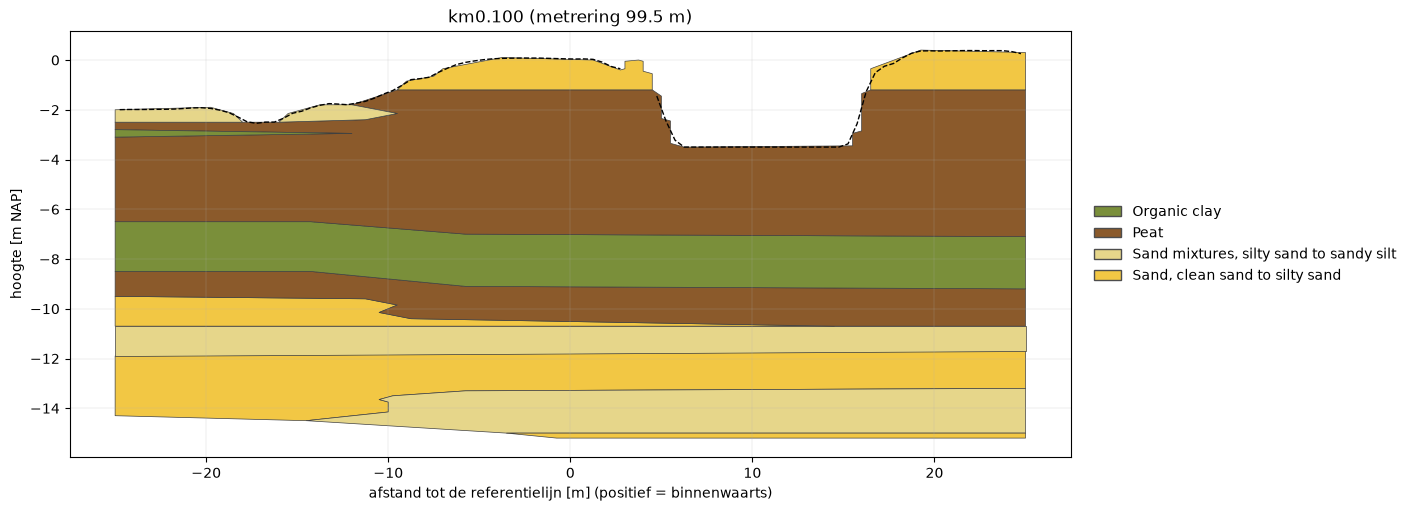

In [3]:
zonder = model.cross_section(100)
print("raakt:", [zone.object for zone in zonder.parameter_areas])
print("grondsoorten:", zonder.soils)
zonder.plot()
plt.show()

## Met de waarden van de parameterzones

Met `use_parameter_area_values=True` krijgt de grondsoort binnen een zone een eigen grondsoort, zoals `Peat (CPT000000074503)`, met de parameters van de zone.

grondsoorten: ['Organic clay', 'Peat (CPT000000074503)', 'Peat (CPT000000074504)', 'Sand mixtures, silty sand to sandy silt', 'Sand, clean sand to silty sand']


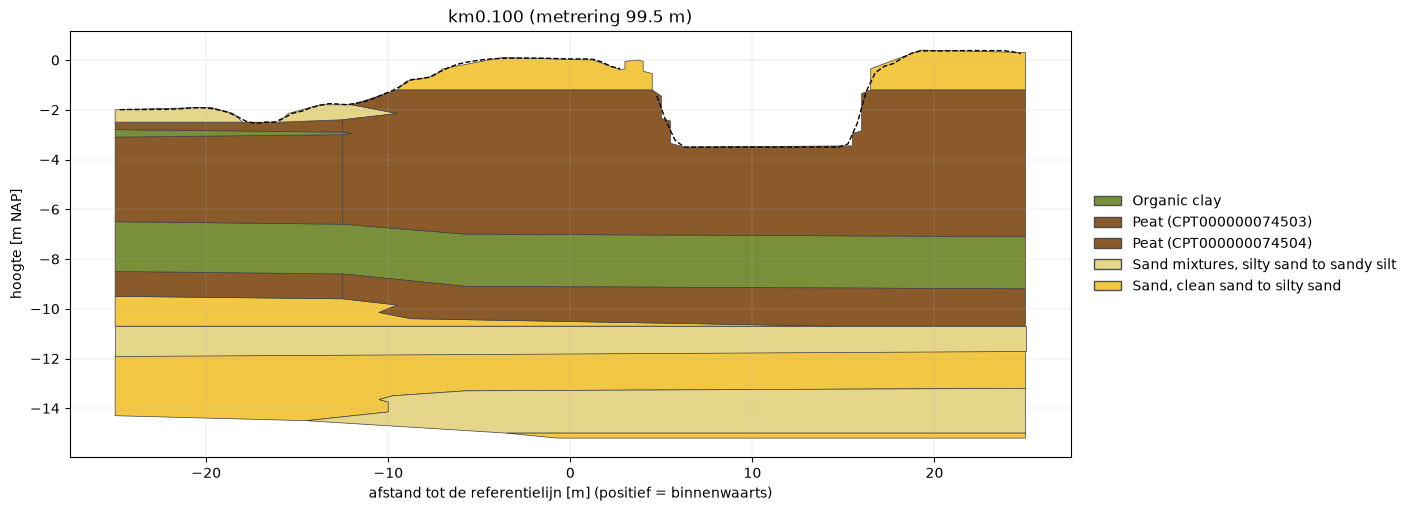

In [4]:
met = model.cross_section(100, use_parameter_area_values=True)
print("grondsoorten:", met.soils)
met.plot()
plt.show()

## In D-Stability

De export schrijft de parameters van de zones in de uitvoer.

In [5]:
from geolib.models.dstability import DStabilityModel

def gewichten(pad):
    stix = DStabilityModel()
    stix.parse(pad)
    for soil in stix.datastructure.soils.Soils:
        print(f"{soil.Code:45s} {soil.VolumetricWeightAbovePhreaticLevel:5.1f} {soil.VolumetricWeightBelowPhreaticLevel:5.1f}")

UITVOER = Path("uitvoer")
UITVOER.mkdir(exist_ok=True)
print("Zonder zones (gamma droog / nat):")
gewichten(zonder.to_dstability(UITVOER / "zonder_zones.stix"))
print("\nMet zones:")
gewichten(met.to_dstability(UITVOER / "met_zones.stix"))

Zonder zones (gamma droog / nat):
Organic clay                                    0.0   0.0
Peat                                            0.0   0.0
Sand mixtures, silty sand to sandy silt         0.0   0.0
Sand, clean sand to silty sand                  0.0   0.0

Met zones:
Organic clay                                    0.0   0.0
Sand mixtures, silty sand to sandy silt         0.0   0.0
Sand, clean sand to silty sand                  0.0   0.0
Peat (CPT000000074503)                         10.0  10.0
Peat (CPT000000074504)                         10.2  10.2


Een grondsoort zonder koppeling aan je eigen `.stix` heeft alleen zijn naam; een grondsoort in een zone heeft de parameters van de zone.